# MetricSuite 5 -- Binary outcomes

Some outcomes are yes/no: *is the estimated peak inside the resected area?*, *was
the spike detected?* Means and medians of 0s and 1s need their own tools:

- **Part 1** -- registering a 0/1 outcome and estimating proportions (Wilson
  interval);
- **Part 2** -- comparing two methods on the same patients: the exact McNemar test;
- **Part 3** -- how large is the difference: the difference in proportions
  (Newcombe interval) and the odds ratio;
- **Part 4** -- plots;
- **Part 5** -- pitfalls.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mindmap.metric import MetricSuite

COLORS = {"wCSET": "#2a78d6", "CSET": "#1baf7a", "dSPM": "#e34948"}
ORDER = ["wCSET", "CSET", "dSPM"]

## 🎯 - Part 1: Registering a 0/1 outcome

### The fake study

40 patients with a resection. For each method we have the distance from the
estimated peak to the resected area -- 0 when the peak lies inside. Patients differ
in difficulty, shared by every method, so outcomes are correlated within a patient.

In [2]:
TRUE_SKILL = {"wCSET": 0.9, "CSET": 0.3, "dSPM": -0.6}   # logit scale
rng = np.random.default_rng(191)
suite = MetricSuite(name="Resection")
for p in range(40):
    difficulty = rng.normal(0, 1.5)
    for method, skill in TRUE_SKILL.items():
        inside = rng.random() < 1 / (1 + np.exp(-(skill - difficulty)))
        distance = 0.0 if inside else rng.gamma(2.0, 6.0)
        suite.register("distance_mm", distance, method=method, patient=f"P{p:02d}")

The binary outcome is a **separate metric**, coded 0/1. Derive it from the
registered distances and register it under its own name:

In [3]:
df = suite.to_df(metrics="distance_mm")
for _, row in df.iterrows():
    suite.register("inside", float(row["Value"] == 0), method=row["method"], patient=row["patient"])

suite.to_df(metrics="inside").head()

,Metric,Value,method,patient
120,inside,0.0,wCSET,P00
121,inside,0.0,CSET,P00
122,inside,0.0,dSPM,P00
123,inside,1.0,wCSET,P01
124,inside,1.0,CSET,P01


### Proportions

The share of patients with the peak inside, per method. `estimate.proportion`
gives the **Wilson** interval. The usual "mean ± 1.96 SE" (Wald) interval misbehaves
for proportions: it can leave [0, 1] and covers less than 95% with small samples or
proportions near 0 or 1. Wilson stays inside [0, 1] and keeps close to 95%.

In [4]:
suite.estimate.proportion("inside", group_by="method").table

,group,estimate,ci_low,ci_high,n,ci_method
0,CSET,0.55,0.398291,0.692947,40,wilson
1,dSPM,0.35,0.221345,0.504941,40,wilson
2,wCSET,0.70,0.545700,0.819252,40,wilson


The data plots take `center="proportion"` too -- with `interval="ci"`, that's the
same Wilson interval:

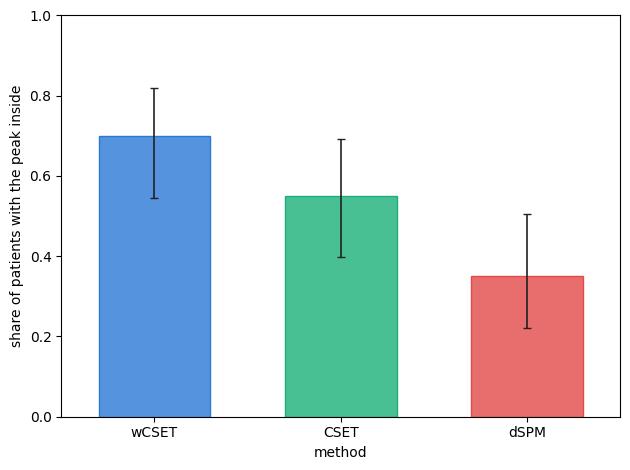

In [5]:
fig, ax = suite.plot.bar("inside", x="method", order=ORDER, palette=COLORS, center="proportion",
                         interval="ci", ylabel="share of patients with the peak inside")
ax.set_ylim(0, 1)
fig.tight_layout()

## ⚖️ - Part 2: Comparing two methods -- McNemar

### Only discordant patients carry information

Pair each patient's outcomes for two methods. Four kinds of patients:

| | CSET inside | CSET outside |
|---|---|---|
| **wCSET inside** | a: both succeed | **b: only wCSET** |
| **wCSET outside** | **c: only CSET** | d: both fail |

Patients in a and d say nothing about which method is better -- both behaved the
same. The comparison rests on the **discordant** ones, b and c. If the methods were
equally good, each discordant patient would be equally likely to fall in b or c: b
out of b + c follows a Binomial(b + c, 1/2). The **exact McNemar test** is that
binomial test -- reliable even with few discordant pairs, unlike the chi-square
approximation.

In [6]:
comparisons = suite.stat.build_comparisons("wCSET", ["CSET", "dSPM"])
mcn = suite.stat.mcnemar("inside", "method", comparisons, pairing_col="patient", correction="holm",
                         effect_sizes=("prop_diff", "odds_ratio"))
mcn

PairwiseResult(metric='inside', test='mcnemar', correction='holm', alpha=0.05, n_comparisons=2)
  wCSET vs CSET: p=0.1796, prop_diff=0.15 [-0.0346, 0.32], odds_ratio=2.5 [0.721, 10.9], n=40
  wCSET vs dSPM: p=0.002625*, prop_diff=0.35 [0.154, 0.508], odds_ratio=8 [1.88, 71.7], n=40

The table reports the discordant counts (`n_a_only` = b, `n_b_only` = c) and
`n_zero`, the concordant pairs (a + d). `vs` names them from the reference's side:

In [7]:
mcn.vs("wCSET")

,p_value,p_corrected,significant,prop_diff,prop_diff_ci_low,prop_diff_ci_high,odds_ratio,odds_ratio_ci_low,odds_ratio_ci_high,offset,alternative,n_pairs,n_zero,n_reference_only,n_competitor_only
method,,,,,,,,,,,,,,,
CSET,0.179565,0.179565,False,0.15,-0.034618,0.320012,2.5,0.721066,10.920469,0.0,two-sided,40,26,10,4
dSPM,0.001312,0.002625,True,0.35,0.153740,0.507501,8.0,1.880844,71.720843,0.0,two-sided,40,22,16,2


McNemar has no `offset`: it tests equal proportions. The table already carries
both effect sizes with their intervals (`prop_diff_ci_low`, `odds_ratio_ci_high`,
...); Part 3 explains them, and `suite.estimate` computes the same numbers on their
own.

## 📏 - Part 3: How large is the difference?

### Difference in proportions, with Newcombe's interval

`prop_diff` = (b - c) / n -- the difference between the two methods' success
rates, in proportion units ("+0.15 = 15 percentage points more patients with the
peak inside"). Concordant patients count in n, so they **dilute** it.

Its interval is **Newcombe's** (1998, method 10): a Wilson interval for each of the
two proportions, combined with their correlation (the patients are the same). It
stays within [-1, 1] and keeps close coverage at small n, unlike the simple Wald
interval.

In [8]:
pdiff = suite.estimate.prop_diff("inside", "method", comparisons, pairing_col="patient")
pdiff.vs("wCSET")

,estimate,ci_low,ci_high,n_reference,n_competitor
method,,,,,
CSET,0.15,-0.034618,0.320012,40,40
dSPM,0.35,0.153740,0.507501,40,40


### Odds ratio

The conditional (McNemar) odds ratio is b / c: among patients where the methods
disagree, how many times more often the reference is the one that succeeds. Its
interval is exact (Clopper-Pearson on b / (b + c), mapped to the odds scale). 1
means no difference; read it on a log scale (2 and 0.5 are equally large effects in
opposite directions). It's `inf` when c = 0.

In [9]:
orat = suite.estimate.odds_ratio("inside", "method", comparisons, pairing_col="patient")
orat.vs("wCSET")

,estimate,ci_low,ci_high,n_reference,n_competitor
method,,,,,
CSET,2.5,0.721066,10.920469,40,40
dSPM,8.0,1.880844,71.720843,40,40


### Which one to report?

They answer different questions:

- `prop_diff` -- "how many more patients does wCSET get right?" Depends on how
  many patients are easy or hopeless for both methods (the concordant ones).
- `odds_ratio` -- "when the methods disagree, how lopsided is it?" Ignores the
  concordant patients.

Add 20 easy patients (inside for every method): the odds ratio doesn't move, the
difference in proportions shrinks.

In [10]:
easy = MetricSuite.concat([suite, MetricSuite(name="Easy")], name="With easy patients")
for p in range(40, 60):
    for method in TRUE_SKILL:
        easy.register("inside", 1.0, method=method, patient=f"P{p:02d}")

pd.concat({
    "40 patients": pd.concat([pdiff.vs("wCSET")["estimate"].rename("prop_diff"),
                              orat.vs("wCSET")["estimate"].rename("odds_ratio")], axis=1),
    "+ 20 easy": pd.concat([
        easy.estimate.prop_diff("inside", "method", comparisons, pairing_col="patient").vs("wCSET")["estimate"].rename("prop_diff"),
        easy.estimate.odds_ratio("inside", "method", comparisons, pairing_col="patient").vs("wCSET")["estimate"].rename("odds_ratio"),
    ], axis=1),
}, axis=1).round(3)

40 patients            + 20 easy           
         prop_diff odds_ratio prop_diff odds_ratio
method                                            
CSET          0.15        2.5     0.100        2.5
dSPM          0.35        8.0     0.233        8.0

A common choice: test with McNemar, report `prop_diff` with its Newcombe interval
(the clinically readable number), plus the discordant counts so readers can see the
odds ratio for themselves.

## 📊 - Part 4: Plots

The stat plots recognize a binary result:

- `group_comparison` defaults to bars of **proportions** with Wilson intervals;
- `paired_differences` draws the test's estimate -- `prop_diff` with its Newcombe
  interval. The per-patient differences are only -1, 0 or +1, so instead of piling
  them up as points, the `"counts"` annotation gives them: b / concordant / c;
- `plot.estimate` of an odds ratio uses a log scale, with the null line at 1.

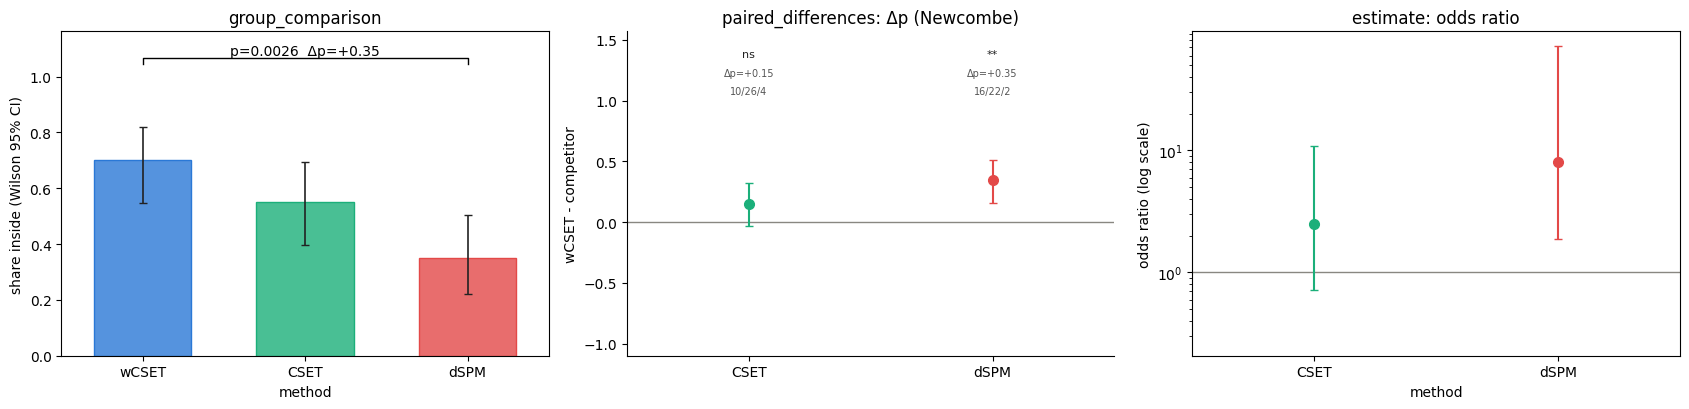

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
suite.plot.group_comparison(mcn, order=ORDER, palette=COLORS, annotate=("p", "prop_diff"), ax=axes[0],
                            ylabel="share inside (Wilson 95% CI)", title="group_comparison")
suite.plot.paired_differences(mcn, palette=COLORS, annotate=("stars", "prop_diff", "counts"), ax=axes[1],
                              ylabel="wCSET - competitor", title="paired_differences: Δp (Newcombe)")
suite.plot.estimate(orat, reference="wCSET", palette=COLORS, ax=axes[2],
                    ylabel="odds ratio (log scale)", title="estimate: odds ratio")
fig.tight_layout()

## ⚠️ - Part 5: Pitfalls

**Only 0/1 values.** McNemar and its effect sizes refuse anything else -- e.g. the
distances themselves:

In [12]:
try:
    suite.stat.mcnemar("distance_mm", "method", comparisons, pairing_col="patient")
except ValueError as e:
    print(e)

McNemar and its effect sizes need a binary outcome coded 0/1 (e.g. register `inside = distance == 0` as its own metric) -- got values such as [2.8134669390156564, 3.2067896476939155, 4.533233594768072]. Averaging repeated 0/1 rows (`unit_col`) gives fractions, which aren't binary either.


**Averaging repeated rows gives fractions.** If each patient were simulated several
times, `unit_col` would average the 0/1 outcomes into fractions (e.g. 2 of 3 runs
inside = 0.67), which aren't binary anymore. Decide what the patient-level outcome
is (e.g. "inside in the majority of runs"), and register that.

**Many ties in a continuous outcome?** If the distance is the primary outcome, test
it with a Wilcoxon test and `zero_method="pratt"` (tutorial 4), and report McNemar
on "inside" alongside -- the two answer complementary questions ("how far off?" vs
"inside or not?").

## Wrap-up

- Register a binary outcome as its own 0/1 metric.
- `estimate.proportion` -- Wilson interval; `center="proportion"` in the plots.
- `stat.mcnemar` -- the exact test for paired 0/1 outcomes; only discordant
  patients count (`n_a_only`, `n_b_only`).
- `estimate.prop_diff` (Newcombe) and `estimate.odds_ratio` (exact) -- the
  effect sizes; concordant patients dilute the first, not the second.
- The stat plots switch to proportions, Δp and a log-scale odds ratio
  automatically.

Next: **tutorial 6** -- the bootstrap.